# Precision–Recall known answer

Before applying precision and recall diagnostics to the five formal defects, we validate the method on small synthetic distributions where the expected behavior is known in advance.

The primary implementation follows Kynkäänniemi et al. (2019). The validation asks whether the metric can distinguish three different distributional failures:

1. loss of coverage / mode dropping;
2. invented off-support mass;
3. strong repetition / concentration of probability mass.

The main setting is $k = 3$.

We also perform a small sensitivity analysis with k = 2, 3, and 5. Precision and recall are kept separate. They are not collapsed into a single $F-score$.

In [1]:
import importlib,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter

import src.paths as paths
import src.prd as prd

importlib.reload(paths)
importlib.reload(prd)

from src.paths import get_project_paths
from src.prd import improved_precision_recall

PATHS=get_project_paths()
WEEK7_RESULTS_DIR=PATHS["results"]/"week7"
WEEK7_RESULTS_DIR.mkdir(parents=True,exist_ok=True)

In [ ]:
# small validation config
PR_N=300
PR_REPS=30
PR_K=3
PR_SCALE=0.45
PR_BASE_SEED=42

print("Samples per distribution:",PR_N)
print("Repetitions:",PR_REPS)
print("Primary k:",PR_K)

Samples per distribution: 300
Repetitions: 30
Primary k: 3


In [ ]:
# define real distribution 
CENTERS=np.array([[-4,-4],[-4,4],[0,0],[4,-4],[4,4]],dtype=float)
EXTRA_CENTER=np.array([[9,0]],dtype=float)

print("Real modes:",len(CENTERS))

Real modes: 5


In [ ]:
# synthetic sampling helper
def sample_modes(centers,n,scale=0.45,weights=None,seed=42):
    rng=np.random.default_rng(seed)
    centers=np.asarray(centers,dtype=float)
    if weights is None: weights=np.ones(len(centers))/len(centers)
    weights=np.asarray(weights,dtype=float); weights=weights/weights.sum()
    idx=rng.choice(len(centers),size=n,p=weights)
    return centers[idx]+rng.normal(0,scale,size=(n,centers.shape[1]))

In [5]:
# fixed known answer example 
real=sample_modes(CENTERS,PR_N,PR_SCALE,seed=1)
matched=sample_modes(CENTERS,PR_N,PR_SCALE,seed=2)
mode_drop=sample_modes(CENTERS[:3],PR_N,PR_SCALE,seed=3)

extra_centers=np.vstack([CENTERS,EXTRA_CENTER])
invented_mass=sample_modes(extra_centers,PR_N,PR_SCALE,weights=[0.16]*5+[0.20],seed=4)

pool=sample_modes(CENTERS,PR_N,PR_SCALE,seed=5)
rng=np.random.default_rng(6)
unique_points=pool[rng.choice(len(pool),size=90,replace=False)]
repetition=np.resize(unique_points,(PR_N,2))

print(real.shape,matched.shape,mode_drop.shape,invented_mass.shape,repetition.shape)

(300, 2) (300, 2) (300, 2) (300, 2) (300, 2)


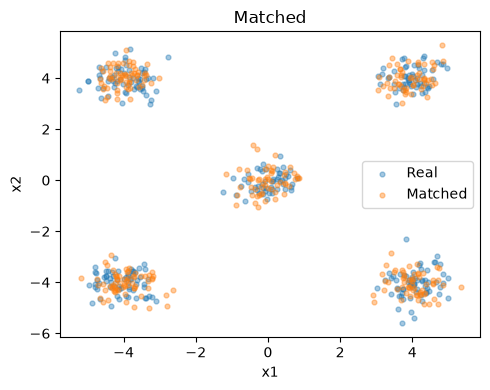

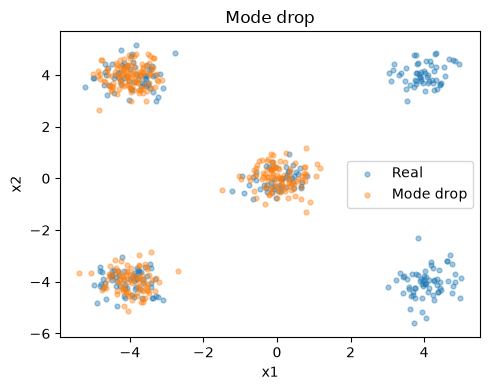

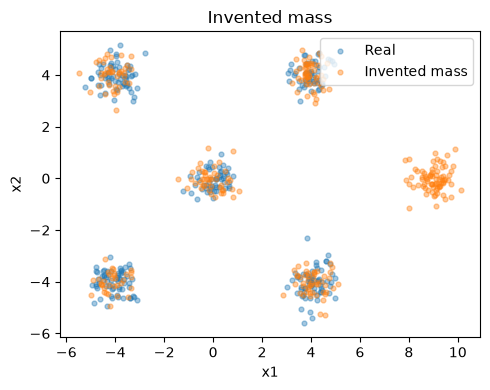

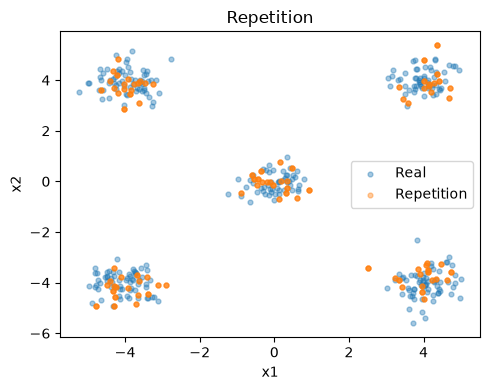

In [6]:
# visualize distributions 
conditions={"Matched":matched,"Mode drop":mode_drop,"Invented mass":invented_mass,"Repetition":repetition}

for name,X in conditions.items():
    plt.figure(figsize=(5,4))
    plt.scatter(real[:,0],real[:,1],s=12,alpha=0.4,label="Real")
    plt.scatter(X[:,0],X[:,1],s=12,alpha=0.4,label=name)
    plt.title(name)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [7]:
# single run sanity check
single_results=[]

for name,X in conditions.items():
    result=improved_precision_recall(real,X,k=PR_K)
    single_results.append({"condition":name,**result})

single_results=pd.DataFrame(single_results)
display(single_results)

,condition,precision,recall,n_real,n_generated,k
0,Matched,0.963333,0.956667,300,300,3
1,Mode drop,0.956667,0.563333,300,300,3
2,Invented mass,0.716667,0.956667,300,300,3
3,Repetition,0.920000,0.536667,300,300,3


In [8]:
# inspect membership directly
single_results["precision_loss"]=1-single_results["precision"]
single_results["recall_loss"]=1-single_results["recall"]
display(single_results[["condition","precision","recall","precision_loss","recall_loss"]])

,condition,precision,recall,precision_loss,recall_loss
0,Matched,0.963333,0.956667,0.036667,0.043333
1,Mode drop,0.956667,0.563333,0.043333,0.436667
2,Invented mass,0.716667,0.956667,0.283333,0.043333
3,Repetition,0.920000,0.536667,0.080000,0.463333


In [9]:
# known answer experiment - 30 independent reps
def build_known_answer_conditions(rep):
    s=PR_BASE_SEED+1000*rep
    real=sample_modes(CENTERS,PR_N,PR_SCALE,seed=s)
    matched=sample_modes(CENTERS,PR_N,PR_SCALE,seed=s+1)
    mode_drop=sample_modes(CENTERS[:3],PR_N,PR_SCALE,seed=s+2)
    invented=sample_modes(np.vstack([CENTERS,EXTRA_CENTER]),PR_N,PR_SCALE,weights=[0.16]*5+[0.20],seed=s+3)
    pool=sample_modes(CENTERS,PR_N,PR_SCALE,seed=s+4)
    rng=np.random.default_rng(s+5)
    unique=pool[rng.choice(len(pool),size=90,replace=False)]
    repetition=np.resize(unique,(PR_N,2))
    return real,{"matched":matched,"mode_drop":mode_drop,"invented_mass":invented,"repetition":repetition}

In [10]:
# run calibration 
records=[]
start=perf_counter()

for rep in range(PR_REPS):
    real,conds=build_known_answer_conditions(rep)
    for name,X in conds.items():
        result=improved_precision_recall(real,X,k=PR_K)
        records.append({"repetition":rep,"condition":name,**result})

pr_runs=pd.DataFrame(records)
print("Rows:",len(pr_runs),"Expected:",PR_REPS*4)
print("Runtime:",round(perf_counter()-start,2),"seconds")

Rows: 120 Expected: 120
Runtime: 3.7 seconds


In [11]:
pr_summary=pr_runs.groupby("condition").agg(repetitions=("repetition","size"),mean_precision=("precision","mean"),std_precision=("precision","std"),mean_recall=("recall","mean"),std_recall=("recall","std")).reset_index()
display(pr_summary)

,condition,repetitions,mean_precision,std_precision,mean_recall,std_recall
0,invented_mass,30,0.763111,0.026333,0.956222,0.018440
1,matched,30,0.951444,0.014561,0.963000,0.011853
2,mode_drop,30,0.954111,0.020467,0.575667,0.026669
3,repetition,30,0.958444,0.022637,0.513444,0.053034


In [12]:
# baseline relative changes 
base=pr_summary.loc[pr_summary["condition"]=="matched"].iloc[0]

pr_summary["precision_change_vs_matched"]=pr_summary["mean_precision"]-base["mean_precision"]
pr_summary["recall_change_vs_matched"]=pr_summary["mean_recall"]-base["mean_recall"]

display(pr_summary)

,condition,repetitions,mean_precision,std_precision,mean_recall,std_recall,precision_change_vs_matched,recall_change_vs_matched
0,invented_mass,30,0.763111,0.026333,0.956222,0.018440,-0.188333,-0.006778
1,matched,30,0.951444,0.014561,0.963000,0.011853,0.000000,0.000000
2,mode_drop,30,0.954111,0.020467,0.575667,0.026669,0.002667,-0.387333
3,repetition,30,0.958444,0.022637,0.513444,0.053034,0.007000,-0.449556


In [13]:
# validation table 
S=pr_summary.set_index("condition")

checks=[
    ("Matched precision is high",S.loc["matched","mean_precision"]>0.85),
    ("Matched recall is high",S.loc["matched","mean_recall"]>0.85),
    ("Mode dropping keeps precision high",S.loc["mode_drop","mean_precision"]>0.85),
    ("Mode dropping lowers recall",S.loc["mode_drop","mean_recall"]<S.loc["matched","mean_recall"]-0.20),
    ("Invented mass lowers precision",S.loc["invented_mass","mean_precision"]<S.loc["matched","mean_precision"]-0.10),
    ("Invented mass keeps recall high",S.loc["invented_mass","mean_recall"]>0.85),
    ("Repetition keeps precision high",S.loc["repetition","mean_precision"]>0.85),
    ("Repetition lowers recall",S.loc["repetition","mean_recall"]<S.loc["matched","mean_recall"]-0.20)
]

validation=pd.DataFrame(checks,columns=["check","passed"])
display(validation)
print("All known-answer checks passed:",validation["passed"].all())

,check,passed
0,Matched precision is high,True
1,Matched recall is high,True
2,Mode dropping keeps precision high,True
3,Mode dropping lowers recall,True
4,Invented mass lowers precision,True
5,Invented mass keeps recall high,True
6,Repetition keeps precision high,True
7,Repetition lowers recall,True


All known-answer checks passed: True


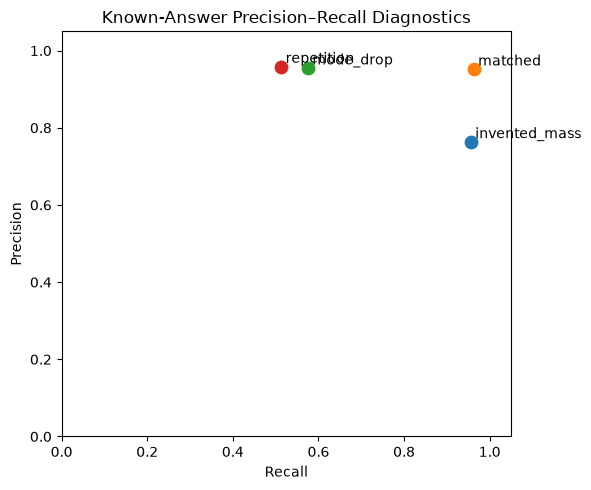

In [14]:
# precision-recall plane 
plt.figure(figsize=(6,5))

for _,row in pr_summary.iterrows():
    plt.scatter(row["mean_recall"],row["mean_precision"],s=80)
    plt.text(row["mean_recall"]+0.01,row["mean_precision"]+0.01,row["condition"])

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Known-Answer Precision–Recall Diagnostics")
plt.xlim(0,1.05)
plt.ylim(0,1.05)
plt.tight_layout()
plt.show()

In [15]:
# k sensitivity check
K_VALUES=[2,3,5]
K_REPS=10
k_records=[]

for k in K_VALUES:
    for rep in range(K_REPS):
        real,conds=build_known_answer_conditions(rep)
        for name,X in conds.items():
            result=improved_precision_recall(real,X,k=k)
            k_records.append({"k":k,"repetition":rep,"condition":name,"precision":result["precision"],"recall":result["recall"]})

k_runs=pd.DataFrame(k_records)
k_summary=k_runs.groupby(["k","condition"]).agg(mean_precision=("precision","mean"),mean_recall=("recall","mean")).reset_index()
display(k_summary)

,k,condition,mean_precision,mean_recall
0,2,invented_mass,0.718333,0.907667
1,2,matched,0.896000,0.922667
2,2,mode_drop,0.904333,0.545667
3,2,repetition,0.903333,0.000000
4,3,invented_mass,0.758333,0.953667
5,3,matched,0.947667,0.962000
6,3,mode_drop,0.953000,0.572333
7,3,repetition,0.952667,0.508667
8,5,invented_mass,0.777667,0.979333
9,5,matched,0.977000,0.983667


In [16]:
# check qualitative stability across k 
k_wide=k_summary.pivot(index="condition",columns="k",values=["mean_precision","mean_recall"])
display(k_wide)

mean_precision                     mean_recall            \
k                          2         3         5           2         3   
condition                                                                
invented_mass       0.718333  0.758333  0.777667    0.907667  0.953667   
matched             0.896000  0.947667  0.977000    0.922667  0.962000   
mode_drop           0.904333  0.953000  0.978333    0.545667  0.572333   
repetition          0.903333  0.952667  0.979333    0.000000  0.508667   

                         
k                     5  
condition                
invented_mass  0.979333  
matched        0.983667  
mode_drop      0.586667  
repetition     0.721000

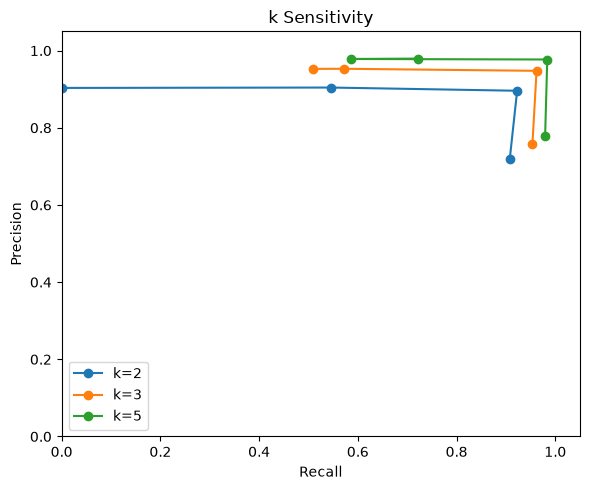

In [17]:
# k sensitivity
plt.figure(figsize=(6,5))

for k in K_VALUES:
    d=k_summary.loc[k_summary["k"]==k]
    plt.plot(d["mean_recall"],d["mean_precision"],marker="o",label=f"k={k}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("k Sensitivity")
plt.xlim(0,1.05)
plt.ylim(0,1.05)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# repetition severity stress test 
# lower number of unique generated observations while keeping n=300
UNIQUE_LEVELS=[300,180,120,90]
rep_stress=[]

real=sample_modes(CENTERS,PR_N,PR_SCALE,seed=700)
pool=sample_modes(CENTERS,PR_N,PR_SCALE,seed=701)

for n_unique in UNIQUE_LEVELS:
    rng=np.random.default_rng(800+n_unique)
    unique=pool[rng.choice(len(pool),size=n_unique,replace=False)]
    generated=np.resize(unique,(PR_N,2))
    result=improved_precision_recall(real,generated,k=PR_K)
    rep_stress.append({"n_unique":n_unique,"unique_fraction":n_unique/PR_N,**result})

rep_stress=pd.DataFrame(rep_stress)
display(rep_stress)

,n_unique,unique_fraction,precision,recall,n_real,n_generated,k
0,300,1.0,0.946667,0.953333,300,300,3
1,180,0.6,0.950000,0.853333,300,300,3
2,120,0.4,0.970000,0.700000,300,300,3
3,90,0.3,0.963333,0.603333,300,300,3


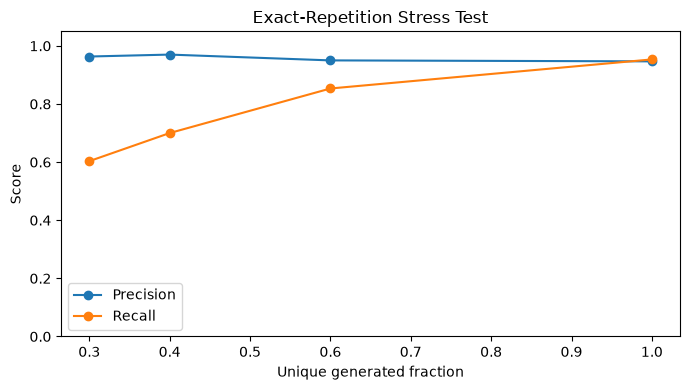

In [19]:
plt.figure(figsize=(7,4))
plt.plot(rep_stress["unique_fraction"],rep_stress["precision"],marker="o",label="Precision")
plt.plot(rep_stress["unique_fraction"],rep_stress["recall"],marker="o",label="Recall")
plt.xlabel("Unique generated fraction")
plt.ylabel("Score")
plt.title("Exact-Repetition Stress Test")
plt.ylim(0,1.05)
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
pr_runs.to_csv(WEEK7_RESULTS_DIR/"ipr_known_answer_runs.csv",index=False)
pr_summary.to_csv(WEEK7_RESULTS_DIR/"ipr_known_answer_summary.csv",index=False)
validation.to_csv(WEEK7_RESULTS_DIR/"ipr_known_answer_checks.csv",index=False)
k_runs.to_csv(WEEK7_RESULTS_DIR/"ipr_k_sensitivity_runs.csv",index=False)
k_summary.to_csv(WEEK7_RESULTS_DIR/"ipr_k_sensitivity_summary.csv",index=False)
rep_stress.to_csv(WEEK7_RESULTS_DIR/"ipr_repetition_stress.csv",index=False)

print("Improved Precision/Recall validation saved.")

Improved Precision/Recall validation saved.


In [21]:
ipr_config={"method":"Improved Precision and Recall, Kynkaanniemi et al. 2019","primary_k":PR_K,"k_sensitivity":[2,3,5],"samples_per_distribution":PR_N,"known_answer_repetitions":PR_REPS,"synthetic_dimension":2,"real_modes":5,"gaussian_scale":PR_SCALE,"equal_sample_sizes":True,"distance":"euclidean","precision_definition":"generated samples inside estimated real manifold","recall_definition":"real samples inside estimated generated manifold","parameter_selection":"paper-based, not tuned on defects"}

with open(WEEK7_RESULTS_DIR/"ipr_validation_configuration.json","w") as f: json.dump(ipr_config,f,indent=4)

print("Configuration saved.")

Configuration saved.


In [22]:
from scipy.sparse import load_npz
from sklearn.preprocessing import StandardScaler

import src.paths as paths
import src.io_utils as io_utils
import src.prd as prd

importlib.reload(paths)
importlib.reload(io_utils)
importlib.reload(prd)

from src.paths import get_project_paths
from src.io_utils import load_embedding_conditions,load_id_file,load_affected_ids_by_severity
from src.prd import repeated_matched_pr,repeated_defect_pr

PATHS=get_project_paths()
DATA_DIR=PATHS["processed"]
WEEK7_RESULTS_DIR=PATHS["results"]/"week7"
WEEK7_RESULTS_DIR.mkdir(parents=True,exist_ok=True)

IPR_REPS=200
IPR_N=100
IPR_K=3
IPR_SEVERITIES=[0.10,0.30,0.60]
IPR_BASE_SEED=42
IPR_BASELINE_SEED=42000


In [23]:
# load template repetition 
template={"clean":load_npz(DATA_DIR/"template_tfidf_clean.npz").toarray().astype(np.float32)}

for s in IPR_SEVERITIES: template[s]=load_npz(DATA_DIR/f"template_tfidf_{int(s*100)}pct.npz").toarray().astype(np.float32)

template_ids=pd.read_csv(DATA_DIR/"template_repetition_formal_eval_ids.csv")["message_id"].astype(str).to_numpy()
template_plan=pd.read_csv(DATA_DIR/"template_repetition_formal_plan.csv")
template_affected={s:set(template_plan.loc[np.isclose(template_plan["severity"],s),"message_id"].astype(str)) for s in IPR_SEVERITIES}

for k,X in template.items(): print(k,X.shape)

clean (300, 5000)
0.1 (300, 5000)
0.3 (300, 5000)
0.6 (300, 5000)


In [24]:
# load broken timing 
structural=pd.read_csv(DATA_DIR/"clean_structural_summary.csv")
train_ids=pd.read_csv(DATA_DIR/"clean_structural_train_scaled.csv")["campaign_id"].astype(str).to_numpy()
bt_ids=pd.read_csv(DATA_DIR/"clean_structural_eval_scaled.csv")["campaign_id"].astype(str).to_numpy()
FEATURES=[c for c in structural.columns if c!="campaign_id"]

struct_idx=structural.set_index("campaign_id")
scaler=StandardScaler().fit(struct_idx.loc[train_ids,FEATURES])

bt={"clean":scaler.transform(struct_idx.loc[bt_ids,FEATURES]).astype(np.float32)}

for s in IPR_SEVERITIES:
    df=pd.read_csv(DATA_DIR/f"broken_timing_structural_{int(s*100)}pct.csv").set_index("campaign_id")
    bt[s]=scaler.transform(df.loc[bt_ids,FEATURES]).astype(np.float32)

bt_plan=pd.read_csv(DATA_DIR/"broken_timing_formal_plan.csv")
bt_affected={s:set(bt_plan.loc[np.isclose(bt_plan["severity"],s),"campaign_id"].astype(str)) for s in IPR_SEVERITIES}

for k,X in bt.items(): print(k,X.shape)

clean (300, 13)
0.1 (300, 13)
0.3 (300, 13)
0.6 (300, 13)


In [25]:
# confirm broken timing scaling 
saved_bt_clean=pd.read_csv(DATA_DIR/"clean_structural_eval_scaled.csv").set_index("campaign_id").loc[bt_ids,FEATURES].to_numpy()
print("Max scaled difference:",np.max(np.abs(bt["clean"]-saved_bt_clean)))

Max scaled difference: 1.3729358627756483e-07


In [26]:
# load entity inconsistency
entity=load_embedding_conditions(DATA_DIR,prefix="entity",severities=(10,30,60))
entity_ids=np.asarray(load_id_file(DATA_DIR,"entity_embedding_campaign_ids.csv",id_column="campaign_id")).astype(str)
entity_affected=load_affected_ids_by_severity(DATA_DIR/"entity_inconsistency_affected_campaign_ids.csv",id_column="campaign_id")

for k,X in entity.items(): print(k,X.shape)

clean (300, 384)
0.1 (300, 384)
0.3 (300, 384)
0.6 (300, 384)


In [27]:
# load missing cross channel reference 
missing=load_embedding_conditions(DATA_DIR,prefix="missing_reference",severities=(10,30,60))
missing_ids=np.asarray(load_id_file(DATA_DIR,"missing_reference_embedding_campaign_ids.csv",id_column="campaign_id")).astype(str)
missing_affected=load_affected_ids_by_severity(DATA_DIR/"missing_reference_affected_campaign_ids.csv",id_column="campaign_id")

for k,X in missing.items(): print(k,X.shape)

clean (300, 384)
0.1 (300, 384)
0.3 (300, 384)
0.6 (300, 384)


In [28]:
# load over polished 
op=load_embedding_conditions(DATA_DIR,prefix="over_polished",severities=(10,30,60))
op_ids=np.asarray(load_id_file(DATA_DIR,"over_polished_embedding_message_ids.csv",id_column="message_id")).astype(str)
op_affected=load_affected_ids_by_severity(DATA_DIR/"over_polished_affected_message_ids.csv",id_column="message_id")

for k,X in op.items(): print(k,X.shape)

clean (300, 384)
0.1 (300, 384)
0.3 (300, 384)
0.6 (300, 384)


In [29]:
# validation 
datasets={"Template":(template,template_ids),"Broken Timing":(bt,bt_ids),"Entity":(entity,entity_ids),"Missing Cross-Channel":(missing,missing_ids),"Over-Polished":(op,op_ids)}

for name,(data,ids) in datasets.items():
    assert len(ids)==300
    assert data["clean"].shape[0]==300
    for s in IPR_SEVERITIES:
        assert data[s].shape==data["clean"].shape
        assert np.isfinite(data[s]).all()
    print(name,"|",data["clean"].shape,"| passed")

Template | (300, 5000) | passed
Broken Timing | (300, 13) | passed
Entity | (300, 384) | passed
Missing Cross-Channel | (300, 384) | passed
Over-Polished | (300, 384) | passed


In [30]:
# registry
registry={
    "Template Repetition":{"data":template,"ids":template_ids,"affected":template_affected,"representation":"TF-IDF"},
    "Broken Timing":{"data":bt,"ids":bt_ids,"affected":bt_affected,"representation":"Structural 13D"},
    "Entity Inconsistency":{"data":entity,"ids":entity_ids,"affected":entity_affected,"representation":"MiniLM campaign"},
    "Missing Cross-Channel":{"data":missing,"ids":missing_ids,"affected":missing_affected,"representation":"MiniLM campaign"},
    "Over-Polished Language":{"data":op,"ids":op_ids,"affected":op_affected,"representation":"MiniLM message"}
}

print("Defects:",len(registry))

Defects: 5


In [31]:
# compute representation specific matched baselines
baseline_records=[]
start=perf_counter()

for defect,cfg in registry.items():
    rows=repeated_matched_pr(cfg["data"]["clean"],n=IPR_N,reps=IPR_REPS,k=IPR_K,seed=IPR_BASELINE_SEED)
    for row in rows: baseline_records.append({"defect":defect,"representation":cfg["representation"],**row})
    print("Completed baseline:",defect)

ipr_baseline_runs=pd.DataFrame(baseline_records)
print("Rows:",len(ipr_baseline_runs),"Expected:",len(registry)*IPR_REPS)
print("Runtime:",round(perf_counter()-start,2),"seconds")

Completed baseline: Template Repetition
Completed baseline: Broken Timing
Completed baseline: Entity Inconsistency
Completed baseline: Missing Cross-Channel
Completed baseline: Over-Polished Language
Rows: 1000 Expected: 1000
Runtime: 27.89 seconds


In [32]:
ipr_baseline_summary=ipr_baseline_runs.groupby(["defect","representation"]).agg(repetitions=("repetition","size"),mean_precision=("precision","mean"),std_precision=("precision","std"),mean_recall=("recall","mean"),std_recall=("recall","std")).reset_index()
display(ipr_baseline_summary)

,defect,representation,repetitions,mean_precision,std_precision,mean_recall,std_recall
0,Broken Timing,Structural 13D,200,0.92245,0.033045,0.93035,0.033481
1,Entity Inconsistency,MiniLM campaign,200,0.85425,0.042973,0.86095,0.039781
2,Missing Cross-Channel,MiniLM campaign,200,0.85425,0.042973,0.86095,0.039781
3,Over-Polished Language,MiniLM message,200,0.87665,0.039472,0.87355,0.043177
4,Template Repetition,TF-IDF,200,0.85795,0.089495,0.85135,0.092734


In [33]:
# run the 5 defects
ipr_records=[]
start=perf_counter()

for defect,cfg in registry.items():
    conditions={s:cfg["data"][s] for s in IPR_SEVERITIES}
    rows=repeated_defect_pr(cfg["data"]["clean"],conditions,ids=cfg["ids"],affected_ids=cfg["affected"],n=IPR_N,reps=IPR_REPS,k=IPR_K,seed=IPR_BASE_SEED)
    for row in rows: ipr_records.append({"defect":defect,"representation":cfg["representation"],**row})
    print("Completed:",defect)

ipr_runs=pd.DataFrame(ipr_records)

print("Rows:",len(ipr_runs))
print("Expected:",len(registry)*len(IPR_SEVERITIES)*IPR_REPS)
print("Runtime:",round(perf_counter()-start,2),"seconds")

Completed: Template Repetition
Completed: Broken Timing
Completed: Entity Inconsistency
Completed: Missing Cross-Channel
Completed: Over-Polished Language
Rows: 3000
Expected: 3000
Runtime: 27.51 seconds


In [34]:
# prevalence check 
ipr_prevalence=ipr_runs.groupby(["defect","severity"]).agg(mean_affected=("n_affected","mean"),std_affected=("n_affected","std"),mean_sample_rate=("sample_affected_rate","mean")).reset_index()
display(ipr_prevalence)

,defect,severity,mean_affected,std_affected,mean_sample_rate
0,Broken Timing,0.1,10.185,2.532358,0.10185
1,Broken Timing,0.3,30.225,4.097355,0.30225
2,Broken Timing,0.6,60.690,4.089931,0.60690
3,Entity Inconsistency,0.1,10.150,2.384519,0.10150
4,Entity Inconsistency,0.3,30.145,3.902579,0.30145
5,Entity Inconsistency,0.6,60.275,3.890379,0.60275
6,Missing Cross-Channel,0.1,10.185,2.532358,0.10185
7,Missing Cross-Channel,0.3,30.225,4.097355,0.30225
8,Missing Cross-Channel,0.6,60.690,4.089931,0.60690
9,Over-Polished Language,0.1,9.900,2.496228,0.09900


In [35]:
ipr_summary=ipr_runs.groupby(["defect","representation","severity"]).agg(repetitions=("repetition","size"),mean_precision=("precision","mean"),std_precision=("precision","std"),mean_recall=("recall","mean"),std_recall=("recall","std"),mean_affected=("n_affected","mean"),mean_sample_rate=("sample_affected_rate","mean")).reset_index()

display(ipr_summary)

,defect,representation,severity,repetitions,mean_precision,std_precision,mean_recall,std_recall,mean_affected,mean_sample_rate
0,Broken Timing,Structural 13D,0.1,200,0.91860,0.034945,0.92545,0.030139,10.185,0.10185
1,Broken Timing,Structural 13D,0.3,200,0.90505,0.039392,0.92410,0.032130,30.225,0.30225
2,Broken Timing,Structural 13D,0.6,200,0.88955,0.042831,0.90530,0.040074,60.690,0.60690
3,Entity Inconsistency,MiniLM campaign,0.1,200,0.86670,0.040064,0.85605,0.042104,10.150,0.10150
4,Entity Inconsistency,MiniLM campaign,0.3,200,0.86590,0.039177,0.85430,0.042302,30.145,0.30145
5,Entity Inconsistency,MiniLM campaign,0.6,200,0.87310,0.039766,0.84670,0.042273,60.275,0.60275
6,Missing Cross-Channel,MiniLM campaign,0.1,200,0.86870,0.041762,0.85315,0.042975,10.185,0.10185
7,Missing Cross-Channel,MiniLM campaign,0.3,200,0.87620,0.037652,0.84260,0.044363,30.225,0.30225
8,Missing Cross-Channel,MiniLM campaign,0.6,200,0.88660,0.035859,0.80950,0.049912,60.690,0.60690
9,Over-Polished Language,MiniLM message,0.1,200,0.87220,0.040601,0.87760,0.041616,9.900,0.09900


In [36]:
# monte carlo uncertainty
ipr_summary["precision_se"]=ipr_summary["std_precision"]/np.sqrt(ipr_summary["repetitions"])
ipr_summary["recall_se"]=ipr_summary["std_recall"]/np.sqrt(ipr_summary["repetitions"])

ipr_summary["precision_ci_lower"]=(ipr_summary["mean_precision"]-1.96*ipr_summary["precision_se"]).clip(0,1)
ipr_summary["precision_ci_upper"]=(ipr_summary["mean_precision"]+1.96*ipr_summary["precision_se"]).clip(0,1)
ipr_summary["recall_ci_lower"]=(ipr_summary["mean_recall"]-1.96*ipr_summary["recall_se"]).clip(0,1)
ipr_summary["recall_ci_upper"]=(ipr_summary["mean_recall"]+1.96*ipr_summary["recall_se"]).clip(0,1)

In [37]:
# merge each defect with its own matched baseline 
baseline_for_merge=ipr_baseline_summary[["defect","mean_precision","mean_recall"]].rename(columns={"mean_precision":"matched_precision","mean_recall":"matched_recall"})
ipr_summary=ipr_summary.merge(baseline_for_merge,on="defect",how="left")

ipr_summary["precision_change_vs_matched"]=ipr_summary["mean_precision"]-ipr_summary["matched_precision"]
ipr_summary["recall_change_vs_matched"]=ipr_summary["mean_recall"]-ipr_summary["matched_recall"]
ipr_summary["precision_loss_vs_matched"]=ipr_summary["matched_precision"]-ipr_summary["mean_precision"]
ipr_summary["recall_loss_vs_matched"]=ipr_summary["matched_recall"]-ipr_summary["mean_recall"]

display(ipr_summary)

,defect,representation,severity,repetitions,mean_precision,std_precision,mean_recall,std_recall,mean_affected,mean_sample_rate,...,precision_ci_lower,precision_ci_upper,recall_ci_lower,recall_ci_upper,matched_precision,matched_recall,precision_change_vs_matched,recall_change_vs_matched,precision_loss_vs_matched,recall_loss_vs_matched
0,Broken Timing,Structural 13D,0.1,200,0.91860,0.034945,0.92545,0.030139,10.185,0.10185,...,0.913757,0.923443,0.921273,0.929627,0.92245,0.93035,-0.00385,-0.00490,0.00385,0.00490
1,Broken Timing,Structural 13D,0.3,200,0.90505,0.039392,0.92410,0.032130,30.225,0.30225,...,0.899591,0.910509,0.919647,0.928553,0.92245,0.93035,-0.01740,-0.00625,0.01740,0.00625
2,Broken Timing,Structural 13D,0.6,200,0.88955,0.042831,0.90530,0.040074,60.690,0.60690,...,0.883614,0.895486,0.899746,0.910854,0.92245,0.93035,-0.03290,-0.02505,0.03290,0.02505
3,Entity Inconsistency,MiniLM campaign,0.1,200,0.86670,0.040064,0.85605,0.042104,10.150,0.10150,...,0.861147,0.872253,0.850215,0.861885,0.85425,0.86095,0.01245,-0.00490,-0.01245,0.00490
4,Entity Inconsistency,MiniLM campaign,0.3,200,0.86590,0.039177,0.85430,0.042302,30.145,0.30145,...,0.860470,0.871330,0.848437,0.860163,0.85425,0.86095,0.01165,-0.00665,-0.01165,0.00665
5,Entity Inconsistency,MiniLM campaign,0.6,200,0.87310,0.039766,0.84670,0.042273,60.275,0.60275,...,0.867589,0.878611,0.840841,0.852559,0.85425,0.86095,0.01885,-0.01425,-0.01885,0.01425
6,Missing Cross-Channel,MiniLM campaign,0.1,200,0.86870,0.041762,0.85315,0.042975,10.185,0.10185,...,0.862912,0.874488,0.847194,0.859106,0.85425,0.86095,0.01445,-0.00780,-0.01445,0.00780
7,Missing Cross-Channel,MiniLM campaign,0.3,200,0.87620,0.037652,0.84260,0.044363,30.225,0.30225,...,0.870982,0.881418,0.836452,0.848748,0.85425,0.86095,0.02195,-0.01835,-0.02195,0.01835
8,Missing Cross-Channel,MiniLM campaign,0.6,200,0.88660,0.035859,0.80950,0.049912,60.690,0.60690,...,0.881630,0.891570,0.802583,0.816417,0.85425,0.86095,0.03235,-0.05145,-0.03235,0.05145
9,Over-Polished Language,MiniLM message,0.1,200,0.87220,0.040601,0.87760,0.041616,9.900,0.09900,...,0.866573,0.877827,0.871832,0.883368,0.87665,0.87355,-0.00445,0.00405,0.00445,-0.00405


In [38]:
ipr_diagnostic=ipr_summary[["defect","severity","mean_precision","mean_recall","matched_precision","matched_recall","precision_change_vs_matched","recall_change_vs_matched"]].copy()
display(ipr_diagnostic)

,defect,severity,mean_precision,mean_recall,matched_precision,matched_recall,precision_change_vs_matched,recall_change_vs_matched
0,Broken Timing,0.1,0.91860,0.92545,0.92245,0.93035,-0.00385,-0.00490
1,Broken Timing,0.3,0.90505,0.92410,0.92245,0.93035,-0.01740,-0.00625
2,Broken Timing,0.6,0.88955,0.90530,0.92245,0.93035,-0.03290,-0.02505
3,Entity Inconsistency,0.1,0.86670,0.85605,0.85425,0.86095,0.01245,-0.00490
4,Entity Inconsistency,0.3,0.86590,0.85430,0.85425,0.86095,0.01165,-0.00665
5,Entity Inconsistency,0.6,0.87310,0.84670,0.85425,0.86095,0.01885,-0.01425
6,Missing Cross-Channel,0.1,0.86870,0.85315,0.85425,0.86095,0.01445,-0.00780
7,Missing Cross-Channel,0.3,0.87620,0.84260,0.85425,0.86095,0.02195,-0.01835
8,Missing Cross-Channel,0.6,0.88660,0.80950,0.85425,0.86095,0.03235,-0.05145
9,Over-Polished Language,0.1,0.87220,0.87760,0.87665,0.87355,-0.00445,0.00405


In [39]:
# precision recall profile table 
ipr_profile_table=ipr_summary.pivot(index="defect",columns="severity",values=["mean_precision","mean_recall"])
display(ipr_profile_table)

mean_precision                   mean_recall           \
severity                          0.1      0.3      0.6         0.1      0.3   
defect                                                                         
Broken Timing                 0.91860  0.90505  0.88955     0.92545  0.92410   
Entity Inconsistency          0.86670  0.86590  0.87310     0.85605  0.85430   
Missing Cross-Channel         0.86870  0.87620  0.88660     0.85315  0.84260   
Over-Polished Language        0.87220  0.86855  0.86940     0.87760  0.87810   
Template Repetition           0.82345  0.77345  0.69275     0.89690  0.88525   

                                 
severity                    0.6  
defect                           
Broken Timing           0.90530  
Entity Inconsistency    0.84670  
Missing Cross-Channel   0.80950  
Over-Polished Language  0.87700  
Template Repetition     0.89415

In [40]:
ipr_loss_table=ipr_summary.pivot(index="defect",columns="severity",values=["precision_loss_vs_matched","recall_loss_vs_matched"])
display(ipr_loss_table)

precision_loss_vs_matched                    \
severity                                     0.1      0.3      0.6   
defect                                                               
Broken Timing                            0.00385  0.01740  0.03290   
Entity Inconsistency                    -0.01245 -0.01165 -0.01885   
Missing Cross-Channel                   -0.01445 -0.02195 -0.03235   
Over-Polished Language                   0.00445  0.00810  0.00725   
Template Repetition                      0.03450  0.08450  0.16520   

                       recall_loss_vs_matched                    
severity                                  0.1      0.3      0.6  
defect                                                           
Broken Timing                         0.00490  0.00625  0.02505  
Entity Inconsistency                  0.00490  0.00665  0.01425  
Missing Cross-Channel                 0.00780  0.01835  0.05145  
Over-Polished Language               -0.00405 -0.00455 -0.00345  
Template Repetition                  -0.04555 -0.03390 -0.04280

In [41]:
# template repetition result 
display(ipr_summary.loc[ipr_summary["defect"]=="Template Repetition",["severity","mean_precision","mean_recall","matched_precision","matched_recall","precision_loss_vs_matched","recall_loss_vs_matched"]])

,severity,mean_precision,mean_recall,matched_precision,matched_recall,precision_loss_vs_matched,recall_loss_vs_matched
12,0.1,0.82345,0.89690,0.85795,0.85135,0.0345,-0.04555
13,0.3,0.77345,0.88525,0.85795,0.85135,0.0845,-0.03390
14,0.6,0.69275,0.89415,0.85795,0.85135,0.1652,-0.04280


In [42]:
# broken timing 
display(ipr_summary.loc[ipr_summary["defect"]=="Broken Timing",["severity","mean_precision","mean_recall","precision_loss_vs_matched","recall_loss_vs_matched"]])

,severity,mean_precision,mean_recall,precision_loss_vs_matched,recall_loss_vs_matched
0,0.1,0.91860,0.92545,0.00385,0.00490
1,0.3,0.90505,0.92410,0.01740,0.00625
2,0.6,0.88955,0.90530,0.03290,0.02505


In [43]:
# entity
display(ipr_summary.loc[ipr_summary["defect"]=="Entity Inconsistency",["severity","mean_precision","mean_recall","precision_loss_vs_matched","recall_loss_vs_matched"]])

,severity,mean_precision,mean_recall,precision_loss_vs_matched,recall_loss_vs_matched
3,0.1,0.8667,0.85605,-0.01245,0.00490
4,0.3,0.8659,0.85430,-0.01165,0.00665
5,0.6,0.8731,0.84670,-0.01885,0.01425


In [44]:
# missing cross channel 
display(ipr_summary.loc[ipr_summary["defect"]=="Missing Cross-Channel",["severity","mean_precision","mean_recall","precision_loss_vs_matched","recall_loss_vs_matched"]])


,severity,mean_precision,mean_recall,precision_loss_vs_matched,recall_loss_vs_matched
6,0.1,0.8687,0.85315,-0.01445,0.00780
7,0.3,0.8762,0.84260,-0.02195,0.01835
8,0.6,0.8866,0.80950,-0.03235,0.05145


In [45]:
# over polished 
display(ipr_summary.loc[ipr_summary["defect"]=="Over-Polished Language",["severity","mean_precision","mean_recall","precision_loss_vs_matched","recall_loss_vs_matched"]])

,severity,mean_precision,mean_recall,precision_loss_vs_matched,recall_loss_vs_matched
9,0.1,0.87220,0.8776,0.00445,-0.00405
10,0.3,0.86855,0.8781,0.00810,-0.00455
11,0.6,0.86940,0.8770,0.00725,-0.00345


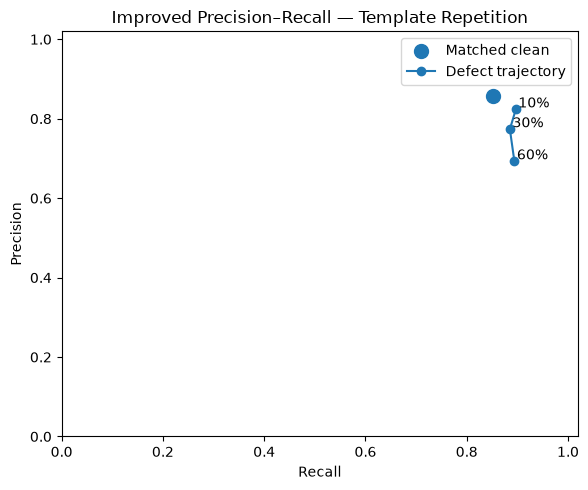

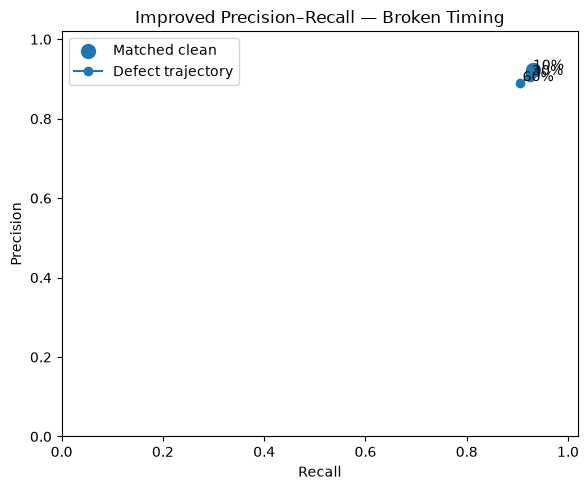

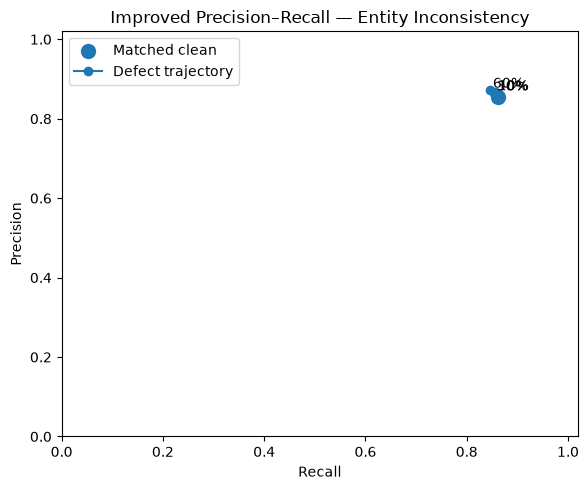

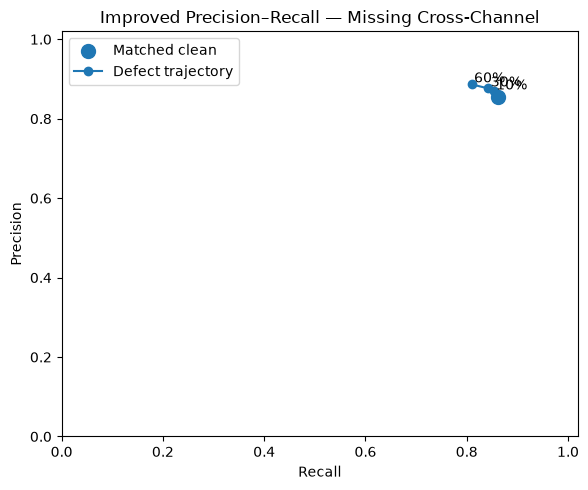

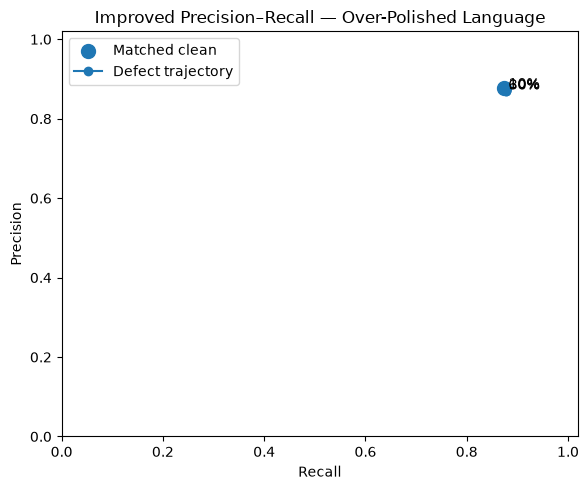

In [46]:
# precision recall trajectory for each defect 
for defect in registry:
    d=ipr_summary.loc[ipr_summary["defect"]==defect].sort_values("severity")
    b=ipr_baseline_summary.loc[ipr_baseline_summary["defect"]==defect].iloc[0]

    plt.figure(figsize=(6,5))
    plt.scatter(b["mean_recall"],b["mean_precision"],s=100,label="Matched clean")
    plt.plot(d["mean_recall"],d["mean_precision"],marker="o",label="Defect trajectory")

    for _,row in d.iterrows(): plt.text(row["mean_recall"]+0.005,row["mean_precision"]+0.005,f"{row['severity']:.0%}")

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Improved Precision–Recall — {defect}")
    plt.xlim(0,1.02)
    plt.ylim(0,1.02)
    plt.legend()
    plt.tight_layout()
    plt.show()

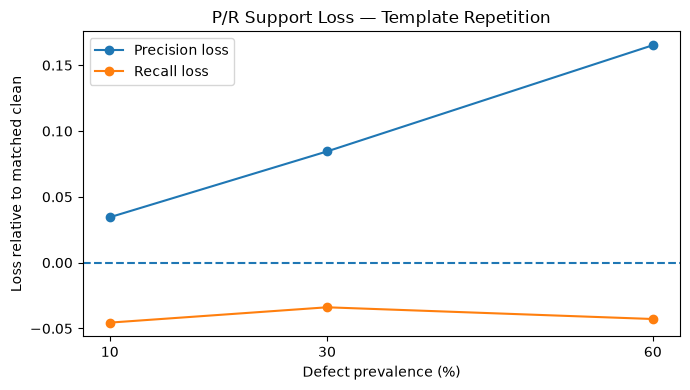

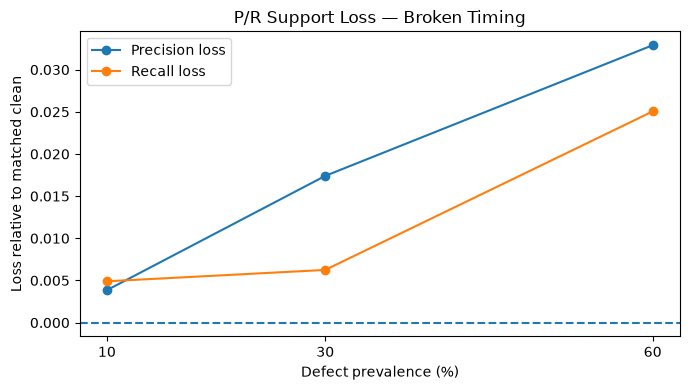

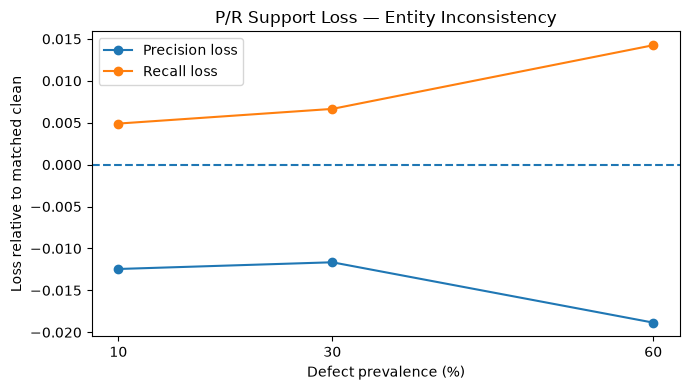

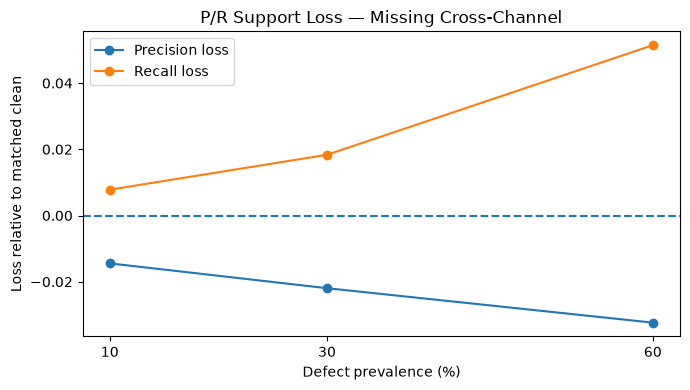

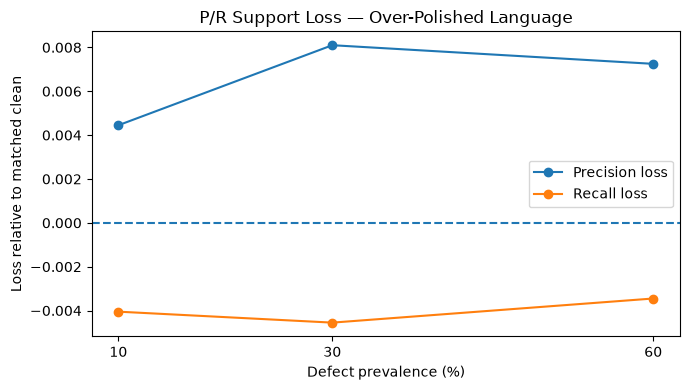

In [47]:
# baseline relative loss trajectories 
for defect in registry:
    d=ipr_summary.loc[ipr_summary["defect"]==defect].sort_values("severity")

    plt.figure(figsize=(7,4))
    plt.plot(d["severity"]*100,d["precision_loss_vs_matched"],marker="o",label="Precision loss")
    plt.plot(d["severity"]*100,d["recall_loss_vs_matched"],marker="o",label="Recall loss")
    plt.axhline(0,linestyle="--")
    plt.xlabel("Defect prevalence (%)")
    plt.ylabel("Loss relative to matched clean")
    plt.title(f"P/R Support Loss — {defect}")
    plt.xticks([10,30,60])
    plt.legend()
    plt.tight_layout()
    plt.show()

In [48]:
# compact 5 defect comparison 
ipr_compact=ipr_summary[["defect","severity","mean_precision","mean_recall","precision_loss_vs_matched","recall_loss_vs_matched"]].round(4)
display(ipr_compact)

,defect,severity,mean_precision,mean_recall,precision_loss_vs_matched,recall_loss_vs_matched
0,Broken Timing,0.1,0.9186,0.9254,0.0039,0.0049
1,Broken Timing,0.3,0.9050,0.9241,0.0174,0.0063
2,Broken Timing,0.6,0.8896,0.9053,0.0329,0.0251
3,Entity Inconsistency,0.1,0.8667,0.8560,-0.0125,0.0049
4,Entity Inconsistency,0.3,0.8659,0.8543,-0.0117,0.0066
5,Entity Inconsistency,0.6,0.8731,0.8467,-0.0189,0.0142
6,Missing Cross-Channel,0.1,0.8687,0.8532,-0.0145,0.0078
7,Missing Cross-Channel,0.3,0.8762,0.8426,-0.0220,0.0183
8,Missing Cross-Channel,0.6,0.8866,0.8095,-0.0323,0.0514
9,Over-Polished Language,0.1,0.8722,0.8776,0.0045,-0.0040


In [49]:
ipr_baseline_runs.to_csv(WEEK7_RESULTS_DIR/"ipr_five_defects_matched_runs.csv",index=False)
ipr_baseline_summary.to_csv(WEEK7_RESULTS_DIR/"ipr_five_defects_matched_summary.csv",index=False)
ipr_runs.to_csv(WEEK7_RESULTS_DIR/"ipr_five_defects_runs.csv",index=False)
ipr_summary.to_csv(WEEK7_RESULTS_DIR/"ipr_five_defects_summary.csv",index=False)
ipr_prevalence.to_csv(WEEK7_RESULTS_DIR/"ipr_five_defects_prevalence.csv",index=False)
ipr_diagnostic.to_csv(WEEK7_RESULTS_DIR/"ipr_five_defects_diagnostic.csv",index=False)
ipr_compact.to_csv(WEEK7_RESULTS_DIR/"ipr_five_defects_compact.csv",index=False)

print("Five-defect Improved Precision/Recall results saved.")

Five-defect Improved Precision/Recall results saved.


In [50]:
ipr_application_config={
    "method":"Improved Precision and Recall, Kynkaanniemi et al. 2019",
    "primary_k":IPR_K,
    "repetitions":IPR_REPS,
    "sample_size_per_distribution":IPR_N,
    "distance":"euclidean",
    "sampling":"disjoint clean and defective IDs within each repetition",
    "same_defective_ids_across_severities":True,
    "matched_baseline":"independent disjoint clean-vs-clean samples",
    "precision":"defective observations inside clean support",
    "recall":"clean observations inside defective support",
    "interpretation":"descriptive support profile, not permutation-test power",
    "defects":list(registry.keys())
}

with open(WEEK7_RESULTS_DIR/"ipr_five_defects_configuration.json","w") as f: json.dump(ipr_application_config,f,indent=4)

print("Configuration saved.")

Configuration saved.


Across the five formal defects, Improved Precision/Recall added a different view from C2ST, MMD, Energy, and Sinkhorn. Broken Timing caused only a small loss in both precision and recall, Entity Inconsistency left support almost unchanged, Missing Cross-Channel showed a clearer recall loss as prevalence increased, and Over-Polished Language produced almost no support-level change despite being highly detectable by MMD and Energy. This reinforces the idea that strong two-sample detectability does not necessarily mean large support or coverage failure.

Template Repetition was the unexpected case. Instead of showing the synthetic known-answer pattern of high precision and lower recall, it showed a strong drop in precision while recall stayed stable or even increased slightly. Because the repeated templates are real SMS taken from the reference set, this may reflect a limitation of estimating support from only 100 clean evaluation points in a sparse 5,000-dimensional TF-IDF space. A real template can still fall outside that finite k-NN approximation, and repeating it many times can amplify the apparent precision loss. The paper also warns that k-NN manifold estimates can behave unexpectedly when probability mass becomes highly concentrated. :chatgpt-content-reference{index="0"}

Before finalizing the five-defect P/R interpretation, we will therefore run a short Template-specific diagnostic. We will check whether the repeated template vectors are actually classified as outside the sampled clean manifold and whether the defective k-NN radii expand as repetition increases. We will also compare the current `n=100` clean manifold with a version built from the larger frozen clean reference set. The goal is not to “fix” the result, but to determine how much of the Template precision drop is a true support effect and how much comes from finite-sample manifold estimation. 

3 questions will be answered:
- Do the two actual templates fall outside the manifold when it is estimated using only n=100 clean evaluation SMS messages?
- Does the drop in precision stem specifically from the affected or repeated messages?
- Does the repetition alter the k-NN radii of Q in a way that could explain the artificially high recall?

In [51]:
import importlib
import src.prd as prd
importlib.reload(prd)

from src.prd import knn_radii,manifold_membership,fit_knn_manifold,membership_from_manifold
from sklearn.metrics import pairwise_distances

In [52]:
# load template artifacts 
from scipy.sparse import load_npz

X_tpl_ref=load_npz(DATA_DIR/"template_tfidf_reference.npz").toarray().astype(np.float32)
X_tpl_clean=load_npz(DATA_DIR/"template_tfidf_clean.npz").toarray().astype(np.float32)
X_tpl={s:load_npz(DATA_DIR/f"template_tfidf_{int(s*100)}pct.npz").toarray().astype(np.float32) for s in [0.10,0.30,0.60]}

tpl_eval_ids=pd.read_csv(DATA_DIR/"template_repetition_formal_eval_ids.csv")["message_id"].astype(str).to_numpy()
tpl_plan=pd.read_csv(DATA_DIR/"template_repetition_formal_plan.csv")
sms_split=pd.read_csv(DATA_DIR/"over_polished_sms_split.csv")
tpl_ref_ids=sms_split.loc[sms_split["split"]=="reference","message_id"].astype(str).to_numpy()

print(X_tpl_ref.shape,X_tpl_clean.shape)
print(len(tpl_ref_ids),len(tpl_eval_ids))

(700, 5000) (300, 5000)
700 300


In [53]:
# identify the frozen samples 
tpl_sources=tpl_plan[["label","template_source_id"]].drop_duplicates().sort_values("label").reset_index(drop=True)
display(tpl_sources)

source_idx=[np.flatnonzero(tpl_ref_ids==sid)[0] for sid in tpl_sources["template_source_id"]]
X_templates=X_tpl_ref[source_idx]

print("Template vectors:",X_templates.shape)
print("Source indices:",source_idx)

,label,template_source_id
0,ham,SMS_2075
1,spam,SMS_2583


Template vectors: (2, 5000)
Source indices: [60, 38]


In [56]:
keep_ref=np.ones(len(X_tpl_ref),dtype=bool)
keep_ref[source_idx]=False

X_tpl_ref_without_templates=X_tpl_ref[keep_ref]
tpl_reference_manifold_without_templates=fit_knn_manifold(X_tpl_ref_without_templates,k=3)

print("Full reference:",X_tpl_ref.shape)
print("Reference without templates:",X_tpl_ref_without_templates.shape)

Full reference: (700, 5000)
Reference without templates: (698, 5000)


In [54]:
# Confirm that the templates are inside the full reference manifold
full_ref_manifold=fit_knn_manifold(X_tpl_ref,k=3)
full_membership=membership_from_manifold(X_templates,full_ref_manifold)

for label,sid,inside in zip(tpl_sources["label"],tpl_sources["template_source_id"],full_membership):
    print(label,sid,"| inside full reference =",inside)

ham SMS_2075 | inside full reference = True
spam SMS_2583 | inside full reference = True


In [55]:
# leave template itself out 
loo_records=[]

for j,row in tpl_sources.iterrows():
    idx=source_idx[j]
    keep=np.arange(len(X_tpl_ref))!=idx
    manifold=fit_knn_manifold(X_tpl_ref[keep],k=3)
    inside=membership_from_manifold(X_templates[j:j+1],manifold)[0]
    loo_records.append({"label":row["label"],"source_id":row["template_source_id"],"inside_reference_without_self":inside})

tpl_leave_one_out=pd.DataFrame(loo_records)
display(tpl_leave_one_out)

,label,source_id,inside_reference_without_self
0,ham,SMS_2075,False
1,spam,SMS_2583,False


In [57]:
# How often are the templates inside an n=100 clean manifold?
TPL_DIAG_REPS=200
sampled_support_records=[]

for rep in range(TPL_DIAG_REPS):
    rng=np.random.default_rng(42+rep)
    idx=rng.choice(len(X_tpl_clean),size=200,replace=False)
    P=X_tpl_clean[idx[:100]]
    inside=manifold_membership(X_templates,P,k=3)
    for j,row in tpl_sources.iterrows():
        sampled_support_records.append({"repetition":rep,"label":row["label"],"source_id":row["template_source_id"],"inside":bool(inside[j])})

tpl_sampled_support=pd.DataFrame(sampled_support_records)
tpl_sampled_support_summary=tpl_sampled_support.groupby(["label","source_id"]).agg(membership_rate=("inside","mean"),times_inside=("inside","sum"),repetitions=("inside","size")).reset_index()

display(tpl_sampled_support_summary)

,label,source_id,membership_rate,times_inside,repetitions
0,ham,SMS_2075,0.53,106,200
1,spam,SMS_2583,0.94,188,200


In [58]:
# Decompose precision into affected vs unaffected messages
tpl_affected={s:set(tpl_plan.loc[np.isclose(tpl_plan["severity"],s),"message_id"].astype(str)) for s in [0.10,0.30,0.60]}
precision_records=[]

for rep in range(TPL_DIAG_REPS):
    rng=np.random.default_rng(42+rep)
    idx=rng.choice(len(X_tpl_clean),size=200,replace=False)
    p_idx,q_idx=idx[:100],idx[100:]
    P=X_tpl_clean[p_idx]
    q_ids=tpl_eval_ids[q_idx]

    for s in [0.10,0.30,0.60]:
        Q=X_tpl[s][q_idx]
        membership=manifold_membership(Q,P,k=3)
        affected=np.array([x in tpl_affected[s] for x in q_ids])
        precision_records.append({"repetition":rep,"severity":s,"precision_all":membership.mean(),"precision_affected":membership[affected].mean() if affected.any() else np.nan,"precision_unaffected":membership[~affected].mean(),"n_affected":affected.sum()})

tpl_precision_decomp=pd.DataFrame(precision_records)
tpl_precision_decomp_summary=tpl_precision_decomp.groupby("severity").agg(precision_all=("precision_all","mean"),precision_affected=("precision_affected","mean"),precision_unaffected=("precision_unaffected","mean"),mean_affected=("n_affected","mean")).reset_index()

display(tpl_precision_decomp_summary)

,severity,precision_all,precision_affected,precision_unaffected,mean_affected
0,0.1,0.82345,0.590454,0.849255,10.075
1,0.3,0.77345,0.586253,0.855028,30.315
2,0.6,0.69275,0.585886,0.853196,60.340


In [59]:
# Diagnose k-NN radii in clean P and defective Q
radius_records=[]

for rep in range(TPL_DIAG_REPS):
    rng=np.random.default_rng(42+rep)
    idx=rng.choice(len(X_tpl_clean),size=200,replace=False)
    p_idx,q_idx=idx[:100],idx[100:]
    P=X_tpl_clean[p_idx]
    rP=knn_radii(P,k=3)

    for s in [0.10,0.30,0.60]:
        Q=X_tpl[s][q_idx]
        rQ=knn_radii(Q,k=3)
        affected=np.array([x in tpl_affected[s] for x in tpl_eval_ids[q_idx]])

        radius_records.append({
            "repetition":rep,"severity":s,
            "clean_mean_radius":rP.mean(),"clean_median_radius":np.median(rP),
            "defect_mean_radius":rQ.mean(),"defect_median_radius":np.median(rQ),
            "defect_q90_radius":np.quantile(rQ,0.90),"defect_max_radius":rQ.max(),
            "zero_radius_rate":np.mean(rQ<=1e-12),
            "affected_mean_radius":rQ[affected].mean() if affected.any() else np.nan,
            "unaffected_mean_radius":rQ[~affected].mean()
        })

tpl_radius_runs=pd.DataFrame(radius_records)
tpl_radius_summary=tpl_radius_runs.groupby("severity").mean(numeric_only=True).reset_index()
display(tpl_radius_summary)

,severity,repetition,clean_mean_radius,clean_median_radius,defect_mean_radius,defect_median_radius,defect_q90_radius,defect_max_radius,zero_radius_rate,affected_mean_radius,unaffected_mean_radius
0,0.1,99.5,1.284926,1.300774,1.188847,1.311480,1.350366,1.412334,0.09140,0.197940,1.301492
1,0.3,99.5,1.284926,1.300774,0.926274,1.303223,1.354437,1.413004,0.29625,0.038075,1.313499
2,0.6,99.5,1.284926,1.300774,0.534002,0.000000,1.362109,1.409952,0.60305,0.001232,1.344785


In [60]:
# compare radius changes relative to clean
tpl_radius_summary["mean_radius_change"]=tpl_radius_summary["defect_mean_radius"]-tpl_radius_summary["clean_mean_radius"]
tpl_radius_summary["median_radius_change"]=tpl_radius_summary["defect_median_radius"]-tpl_radius_summary["clean_median_radius"]

display(tpl_radius_summary[["severity","clean_mean_radius","defect_mean_radius","mean_radius_change","zero_radius_rate","affected_mean_radius","unaffected_mean_radius","defect_q90_radius"]])

,severity,clean_mean_radius,defect_mean_radius,mean_radius_change,zero_radius_rate,affected_mean_radius,unaffected_mean_radius,defect_q90_radius
0,0.1,1.284926,1.188847,-0.096079,0.09140,0.197940,1.301492,1.350366
1,0.3,1.284926,0.926274,-0.358651,0.29625,0.038075,1.313499,1.354437
2,0.6,1.284926,0.534002,-0.750923,0.60305,0.001232,1.344785,1.362109


In [61]:
# Determine which Q spheres are covering clean P points
coverage_records=[]

for rep in range(TPL_DIAG_REPS):
    rng=np.random.default_rng(42+rep)
    idx=rng.choice(len(X_tpl_clean),size=200,replace=False)
    p_idx,q_idx=idx[:100],idx[100:]
    P=X_tpl_clean[p_idx]

    for s in [0.10,0.30,0.60]:
        Q=X_tpl[s][q_idx]
        rQ=knn_radii(Q,k=3)
        D=pairwise_distances(P,Q)
        affected=np.array([x in tpl_affected[s] for x in tpl_eval_ids[q_idx]])
        covered=D<=rQ[None,:]
        any_cover=covered.any(axis=1)
        by_aff=covered[:,affected].any(axis=1) if affected.any() else np.zeros(len(P),dtype=bool)
        by_unaff=covered[:,~affected].any(axis=1)
        coverage_records.append({"repetition":rep,"severity":s,"recall":any_cover.mean(),"covered_by_affected":by_aff.mean(),"covered_by_unaffected":by_unaff.mean(),"covered_only_by_affected":np.mean(by_aff&~by_unaff),"covered_only_by_unaffected":np.mean(by_unaff&~by_aff)})

tpl_coverage_runs=pd.DataFrame(coverage_records)
tpl_coverage_summary=tpl_coverage_runs.groupby("severity").mean(numeric_only=True).reset_index()
display(tpl_coverage_summary)

,severity,repetition,recall,covered_by_affected,covered_by_unaffected,covered_only_by_affected,covered_only_by_unaffected
0,0.1,99.5,0.98480,0.02385,0.98435,0.00045,0.96095
1,0.3,99.5,0.97630,0.00870,0.97615,0.00015,0.96760
2,0.6,99.5,0.96715,0.00055,0.96715,0.00000,0.96660


In [62]:
tpl_reference_manifold=fit_knn_manifold(X_tpl_ref,k=3)

ref_compare_records=[]

for rep in range(TPL_DIAG_REPS):
    rng=np.random.default_rng(42+rep)
    idx=rng.choice(len(X_tpl_clean),size=200,replace=False)
    p_idx,q_idx=idx[:100],idx[100:]
    P=X_tpl_clean[p_idx]
    clean_Q=X_tpl_clean[q_idx]

    for s in [0.10,0.30,0.60]:
        Q=X_tpl[s][q_idx]
        ref_compare_records.append({
            "repetition":rep,
            "severity":s,
            "sampled_clean_precision":manifold_membership(clean_Q,P,k=3).mean(),
            "sampled_defect_precision":manifold_membership(Q,P,k=3).mean(),
            "full_reference_clean_precision":membership_from_manifold(clean_Q,tpl_reference_manifold).mean(),
            "full_reference_defect_precision":membership_from_manifold(Q,tpl_reference_manifold).mean(),
            "source_excluded_clean_precision":membership_from_manifold(clean_Q,tpl_reference_manifold_without_templates).mean(),
            "source_excluded_defect_precision":membership_from_manifold(Q,tpl_reference_manifold_without_templates).mean()
        })

tpl_ref_compare=pd.DataFrame(ref_compare_records)
tpl_ref_compare_summary=tpl_ref_compare.groupby("severity").mean(numeric_only=True).reset_index()

display(tpl_ref_compare_summary)

,severity,repetition,sampled_clean_precision,sampled_defect_precision,full_reference_clean_precision,full_reference_defect_precision,source_excluded_clean_precision,source_excluded_defect_precision
0,0.1,99.5,0.8518,0.82345,0.14725,0.23405,0.14725,0.13330
1,0.3,99.5,0.8518,0.77345,0.14725,0.41360,0.14725,0.11045
2,0.6,99.5,0.8518,0.69275,0.14725,0.66220,0.14725,0.05880


In [63]:
tpl_ref_compare_summary["sampled_change"]=tpl_ref_compare_summary["sampled_defect_precision"]-tpl_ref_compare_summary["sampled_clean_precision"]
tpl_ref_compare_summary["full_reference_change"]=tpl_ref_compare_summary["full_reference_defect_precision"]-tpl_ref_compare_summary["full_reference_clean_precision"]
tpl_ref_compare_summary["source_excluded_change"]=tpl_ref_compare_summary["source_excluded_defect_precision"]-tpl_ref_compare_summary["source_excluded_clean_precision"]

display(tpl_ref_compare_summary[[
    "severity",
    "sampled_change",
    "full_reference_change",
    "source_excluded_change"
]])

,severity,sampled_change,full_reference_change,source_excluded_change
0,0.1,-0.02835,0.08680,-0.01395
1,0.3,-0.07835,0.26635,-0.03680
2,0.6,-0.15905,0.51495,-0.08845


In [64]:
#  full-reference precision for affected vs unaffected Q
ref_decomp_records=[]

for rep in range(TPL_DIAG_REPS):
    rng=np.random.default_rng(42+rep)
    idx=rng.choice(len(X_tpl_clean),size=200,replace=False)
    q_idx=idx[100:]
    q_ids=tpl_eval_ids[q_idx]

    for s in [0.10,0.30,0.60]:
        Q=X_tpl[s][q_idx]
        membership=membership_from_manifold(Q,tpl_reference_manifold)
        affected=np.array([x in tpl_affected[s] for x in q_ids])
        ref_decomp_records.append({"repetition":rep,"severity":s,"all":membership.mean(),"affected":membership[affected].mean() if affected.any() else np.nan,"unaffected":membership[~affected].mean()})

tpl_ref_decomp=pd.DataFrame(ref_decomp_records)
tpl_ref_decomp_summary=tpl_ref_decomp.groupby("severity").mean(numeric_only=True).reset_index()
display(tpl_ref_decomp_summary)

,severity,repetition,all,affected,unaffected
0,0.1,99.5,0.23405,1.0,0.148308
1,0.3,99.5,0.41360,1.0,0.158485
2,0.6,99.5,0.66220,1.0,0.147893


In [ ]:
tpl_leave_one_out.to_csv(WEEK7_RESULTS_DIR/"ipr_template_leave_one_out_support.csv",index=False)
tpl_sampled_support_summary.to_csv(WEEK7_RESULTS_DIR/"ipr_template_sampled_support.csv",index=False)
tpl_precision_decomp_summary.to_csv(WEEK7_RESULTS_DIR/"ipr_template_precision_decomposition.csv",index=False)
tpl_radius_summary.to_csv(WEEK7_RESULTS_DIR/"ipr_template_radius_diagnostic.csv",index=False)
tpl_coverage_summary.to_csv(WEEK7_RESULTS_DIR/"ipr_template_coverage_sources.csv",index=False)
tpl_ref_compare_summary.to_csv(WEEK7_RESULTS_DIR/"ipr_template_reference_comparison.csv",index=False)
tpl_ref_decomp_summary.to_csv(WEEK7_RESULTS_DIR/"ipr_template_reference_decomposition.csv",index=False)

print("Template IPR diagnostics saved.")

In [65]:
tpl_recall_recheck=[]

for rep in range(IPR_REPS):
    rng=np.random.default_rng(IPR_BASE_SEED+rep)
    idx=rng.choice(len(X_tpl_clean),size=2*IPR_N,replace=False)
    p_idx,q_idx=idx[:IPR_N],idx[IPR_N:]
    P=X_tpl_clean[p_idx]

    for s in IPR_SEVERITIES:
        Q=X_tpl[s][q_idx]
        direct=manifold_membership(P,Q,k=IPR_K).mean()
        tpl_recall_recheck.append({"repetition":rep,"severity":s,"direct_recall":direct})

tpl_recall_recheck=pd.DataFrame(tpl_recall_recheck)

original=ipr_runs.loc[ipr_runs["defect"]=="Template Repetition",["repetition","severity","recall"]]
check=original.merge(tpl_recall_recheck,on=["repetition","severity"])
check["difference"]=check["recall"]-check["direct_recall"]

display(check.groupby("severity").agg(
    original_recall=("recall","mean"),
    direct_recall=("direct_recall","mean"),
    mean_difference=("difference","mean"),
    max_abs_difference=("difference",lambda x:np.abs(x).max())
).reset_index())

,severity,original_recall,direct_recall,mean_difference,max_abs_difference
0,0.1,0.89690,0.89690,0.0,0.0
1,0.3,0.88525,0.88525,0.0,0.0
2,0.6,0.89415,0.89415,0.0,0.0


### PRD Validation

At 10% prevalence, affected observations cover only about:

$$2.4\%$$

of clean query points.

At 30%, this decreases to:

$$0.9\%$$

At 60%, it is essentially:

$$0.05\%$$

More importantly, the fraction covered exclusively by affected observations is almost zero at every severity.

By 60%:

$$\text{Covered only by affected} = 0$$

The repeated templates are therefore not maintaining recall.


#### coverage comes from the remaining unique observations

The unaffected observations account for essentially the entire observed coverage:

$$0.984 \rightarrow 0.976 \rightarrow 0.967$$

At 60%, total recall and coverage by unaffected observations are numerically identical:

$$\text{Recall} = 0.96715 \quad \text{and} \quad \text{Covered}_{\text{unaffected}} = 0.96715$$

This confirms the interpretation suggested by the radius diagnostic:
* Repeated points collapse into extremely small local neighborhoods and cover almost none of the clean distribution.
* The remaining unique observations develop slightly larger neighborhoods and provide nearly all of the estimated support coverage.


#### What template repetition is doing to the k-NN manifold

1. **Mass Concentration:** Increasing repetition places more probability mass on two isolated real observations.
2. **Lack of Reference Support:** These observations are not consistently supported by independently sampled clean TF-IDF manifolds.
3. **Precision Decrease:** Concentrating mass on off-manifold points produces a progressive precision drop.
4. **Zero-Radius Collapse:** Exact duplicates generate many nearly zero-radius neighborhoods.
5. **Negligible Recall Contribution:** Repeated neighborhoods contribute almost nothing to overall recall.
6. **Sparser Unique Support:** The remaining unique observations become more sparsely distributed.
7. **Radius Expansion:** K-NN radii for remaining unique points expand slightly.
8. **Primary Support Maintenance:** These remaining observations provide almost all of the estimated clean coverage.

This geometric decomposition provides far deeper diagnostic value than simply reporting a drop in precision.


#### Why the Synthetic Repetition Experiment Behaved Differently

The synthetic known-answer experiment yielded:

$$\text{Precision} \approx \text{stable} \quad \text{and} \quad \text{Recall} \downarrow$$

The real Template experiment behaves differently because the two experiments do not share the same underlying geometry:

* **Synthetic Setup:** Repeated observations were sampled from smooth, well-populated 2D Gaussian modes (typical members of dense regions).
* **Real Setup:** Repeated observations are two specific high-dimensional sparse TF-IDF vectors, both shown to sit outside reference support when their exact source point is removed.

Therefure, real template repetition does not merely reduce diversity; it concentrates mass on unusual lexical locations. Consequently, it should not be categorized as a pure mode-collapse phenomenon.

For this specific defect and representation, Template Repetition combines two distinct mechanics:
1. Concentration of probability mass.
2. Concentration on sparsely supported lexical observations.

The second effect generates a distinct precision signal. This represents a valuable negative finding rather than an experimental artifact requiring correction.


#### Precision/Recall Diagnostic Value

Template Repetition exhibited extremely high two-sample power at 10% prevalence:

$$\text{Energy} = 0.95, \quad \text{MMD} = 0.95, \quad \text{Sinkhorn} = 0.97$$

While these metrics proved the distributions were statistically distinct, they failed to explain the structural cause. Precision/Recall diagnostics fill this gap:

| Metric Type | Diagnostic Question Answered |
| :--- | :--- |
| **Two-Sample Tests** | *Are the distributions detectably different?* |
| **Support Diagnostics** | *What kind of geometric mismatch is producing that difference?* |

The Template Precision/Recall findings should be preserved without modification to force a hypothetical recall-loss pattern. The observed precision loss is fully explainable and reproducible, arising from the intersection of:

$$\text{Exact Repetition} \times \text{Sparse TF-IDF Geometry} \times \text{Finite-Sample } k\text{-NN Support Estimation}$$

This reinforces the central project principle:

$$\text{Metric Response} \neq \text{Defect Label Alone}$$